# Tecnológico Nacional de México - Instituto Tecnológico de Ciudad Madero
### Departamento de Sistemas y Computación | Ingeniería en Sistemas Computacionales
**Asignatura:** Tópicos Avanzados de Programación  
**Docente:** Alejandro Estrada Padilla  
**Práctica de Laboratorio:** Análisis y visualización de calificaciones con Pandas y Matplotlib  
**Entregable:** `practica_pandas.ipynb`  

---
### Objetivo:
Cargar un archivo CSV en un DataFrame de Pandas, filtrar registros, construir columnas calculadas, resumir información mediante agrupaciones (`groupby`) y comunicar los resultados a través de visualizaciones con Matplotlib.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Configuración visual de Matplotlib para notebooks interactivos
%matplotlib inline
plt.rcParams['figure.dpi'] = 100

# Verificación de la ruta del archivo CSV
RUTA_CSV = Path("calificaciones_isc.csv")
if not RUTA_CSV.exists():
    RUTA_CSV = Path(r"calificaciones_isc.csv")

print("Librerías importadas correctamente.")
print(f"Ruta del dataset: {RUTA_CSV}")

Librerías importadas correctamente.
Ruta del dataset: calificaciones_isc.csv


---
## Ejercicio 1: Carga y Revisión de Datos
1. Leer `calificaciones_isc.csv` en un DataFrame llamado `df`.
2. Imprimir las primeras 5 filas (`.head()`).
3. Imprimir el número de filas y columnas (`.shape`).
4. Imprimir el tipo de dato de cada columna (`.dtypes`).
5. Imprimir el resumen estadístico (`.describe()`) de `calificacion` y `asistencias`.
6. Explicar por qué hay **288 registros** y no **24**.

In [2]:
# 1.1 Carga del dataset en el DataFrame df
df = pd.read_csv("calificaciones_isc.csv")

print("=" * 60)
print("1. PRIMERAS 5 FILAS DEL DATAFRAME")
print("=" * 60)
display(df.head())

print("\n" + "=" * 60)
print("2. DIMENSIONES (FILAS Y COLUMNAS)")
print("=" * 60)
print(f"Total de registros (filas): {df.shape[0]}")
print(f"Total de atributos (columnas): {df.shape[1]}")
print(f"df.shape = {df.shape}")

print("\n" + "=" * 60)
print("3. TIPOS DE DATOS POR COLUMNA (df.dtypes)")
print("=" * 60)
print(df.dtypes)

print("\n" + "=" * 60)
print("4. RESUMEN ESTADÍSTICO DE 'calificacion' Y 'asistencias'")
print("=" * 60)
display(df[["calificacion", "asistencias"]].describe().round(2))

# -----------------------------------------------------------------------------
# EXPLICACIÓN: ¿Por qué hay 288 registros y no 24?
# Cada fila no representa un resumen global del alumno, sino una evaluación individual
# correspondiente a una unidad específica de una materia cursada:
#   24 estudiantes en total (12 Grupo A + 12 Grupo B)
#   × 4 materias (Programación, Bases de datos, Redes, Matemáticas discretas)
#   × 3 unidades evaluadas por materia
#   = 24 × 4 × 3 = 288 registros en total.
# -----------------------------------------------------------------------------

1. PRIMERAS 5 FILAS DEL DATAFRAME
   matricula     nombre grupo         materia  unidad  calificacion  asistencias
0  ISC240100  Ana Lopez     A    Programacion       1            55            5
1  ISC240100  Ana Lopez     A    Programacion       2            54            5
2  ISC240100  Ana Lopez     A    Programacion       3            50            8
3  ISC240100  Ana Lopez     A  Bases de datos       1            76            6
4  ISC240100  Ana Lopez     A  Bases de datos       2            73            5

2. DIMENSIONES (FILAS Y COLUMNAS)
Total de registros (filas): 288
Total de atributos (columnas): 7
df.shape = (288, 7)

3. TIPOS DE DATOS POR COLUMNA (df.dtypes)
matricula       object
nombre          object
grupo           object
materia         object
unidad           int64
calificacion     int64
asistencias      int64
dtype: object

4. RESUMEN ESTADÍSTICO DE 'calificacion' Y 'asistencias'
       calificacion  asistencias
count        288.00       288.00
mean          73.8

---
## Ejercicio 2: Filtros Condicionales
Obtener y contar las filas sin modificar `df`, utilizando máscaras booleanas y `len()` (sin ciclos `for`):
1. Solo alumnos del **Grupo A**.
2. Unidades con calificación menor a **70** (no acreditadas).
3. Materia **"Bases de datos"**, del **Grupo B**, con calificación **>= 80**.

In [3]:
# 2.1 Filtro: Solo el Grupo A
filtro_grupo_a = df[df["grupo"] == "A"]
conteo_grupo_a = len(filtro_grupo_a)

# 2.2 Filtro: Calificaciones menores a 70
filtro_menor_70 = df[df["calificacion"] < 70]
conteo_menor_70 = len(filtro_menor_70)

# 2.3 Filtro: 'Bases de datos', Grupo B, calificación >= 80
mascara_bd_b_80 = (df["materia"] == "Bases de datos") & (df["grupo"] == "B") & (df["calificacion"] >= 80)
filtro_bd_b_80 = df[mascara_bd_b_80]
conteo_bd_b_80 = len(filtro_bd_b_80)

print(f"1. Filas pertenecientes únicamente al Grupo A: {conteo_grupo_a}")
print(f"2. Unidades con calificación menor a 70: {conteo_menor_70}")
print(f"3. 'Bases de datos' del Grupo B con calificación >= 80: {conteo_bd_b_80}")

1. Filas pertenecientes únicamente al Grupo A: 144
2. Unidades con calificación menor a 70: 110
3. 'Bases de datos' del Grupo B con calificación >= 80: 18


---
## Ejercicio 3: Columna Calculada (`situacion`)
Crear en `df` la columna `situacion`:
* `"Aprobado"` si `calificacion >= 70`
* `"Reprobado"` en cualquier otro caso  
*Implementación vectorizada con `np.where` (sin ciclos).*

In [4]:
# Creación vectorizada de la columna 'situacion' con np.where
df["situacion"] = np.where(df["calificacion"] >= 70, "Aprobado", "Reprobado")

print("Columna 'situacion' creada con éxito.")
display(df[["matricula", "nombre", "materia", "unidad", "calificacion", "situacion"]].head(8))

Columna 'situacion' creada con éxito.
   matricula     nombre         materia  unidad  calificacion  situacion
0  ISC240100  Ana Lopez    Programacion       1            55  Reprobado
1  ISC240100  Ana Lopez    Programacion       2            54  Reprobado
2  ISC240100  Ana Lopez    Programacion       3            50  Reprobado
3  ISC240100  Ana Lopez  Bases de datos       1            76   Aprobado
4  ISC240100  Ana Lopez  Bases de datos       2            73   Aprobado
5  ISC240100  Ana Lopez  Bases de datos       3            74   Aprobado
6  ISC240100  Ana Lopez           Redes       1            99   Aprobado
7  ISC240100  Ana Lopez           Redes       2            79   Aprobado


---
## Ejercicio 4: Resúmenes Estadísticos y Exportación
Cálculo de métricas agregadas con `groupby()`:
1. Promedio por **materia**.
2. Promedio por **grupo y materia**.
3. Promedio general de cada **alumno** (orden descendente).
4. Promedio general por **unidad** (todas las materias combinadas).
5. Conteo de unidades **aprobadas vs reprobadas**.
6. Exportación de promedios de alumnos a `promedios_alumnos.csv` usando `.reset_index()` e `index=False`.

In [5]:
# 4.1 Promedio por materia
promedio_materia = df.groupby("materia")["calificacion"].mean().round(2)
print("--- 1. PROMEDIO POR MATERIA ---")
print(promedio_materia)

# 4.2 Promedio por grupo y materia
promedio_grupo_materia = df.groupby(["grupo", "materia"])["calificacion"].mean().round(2)
print("\n--- 2. PROMEDIO POR GRUPO Y MATERIA ---")
print(promedio_grupo_materia)

# 4.3 Promedio general por alumno (orden descendente)
promedio_por_alumno = (
    df.groupby(["matricula", "nombre"])["calificacion"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)
print("\n--- 3. PROMEDIO POR ALUMNO (TOP 5) ---")
print(promedio_por_alumno.head(5))

# 4.4 Promedio general por unidad
promedio_por_unidad = df.groupby("unidad")["calificacion"].mean().round(2)
print("\n--- 4. PROMEDIO POR UNIDAD (TODAS LAS MATERIAS) ---")
print(promedio_por_unidad)

# 4.5 Conteo de aprobados vs reprobados
conteo_situacion = df["situacion"].value_counts()
print("\n--- 5. CONTEO DE UNIDADES APROBADAS VS REPROBADAS ---")
print(conteo_situacion)

# 4.6 Exportar a CSV conservando matricula y nombre sin índice numérico
df_promedios_export = (
    df.groupby(["matricula", "nombre"])["calificacion"]
    .mean()
    .round(2)
    .reset_index()
    .rename(columns={"calificacion": "promedio"})
    .sort_values(by="promedio", ascending=False)
)

archivo_export = "promedios_alumnos.csv"
df_promedios_export.to_csv(archivo_export, index=False)
print(f"\n--- 6. EXPORTACIÓN A CSV ---")
print(f"Archivo '{archivo_export}' guardado exitosamente.")
display(df_promedios_export.head())

--- 1. PROMEDIO POR MATERIA ---
materia
Bases de datos           75.06
Matematicas discretas    73.04
Programacion             73.94
Redes                    73.21
Name: calificacion, dtype: float64

--- 2. PROMEDIO POR GRUPO Y MATERIA ---
grupo  materia              
A      Bases de datos           73.89
       Matematicas discretas    72.81
       Programacion             73.28
       Redes                    73.00
B      Bases de datos           76.22
       Matematicas discretas    73.28
       Programacion             74.61
       Redes                    73.42
Name: calificacion, dtype: float64

--- 3. PROMEDIO POR ALUMNO (TOP 5) ---
matricula  nombre         
ISC240117  Ricardo Castro     82.58
ISC240116  Paola Ortiz        77.50
ISC240108  Mariana Torres     77.33
ISC240103  Diego Hernandez    77.08
ISC240112  Brenda Diaz        77.08
Name: calificacion, dtype: float64

--- 4. PROMEDIO POR UNIDAD (TODAS LAS MATERIAS) ---
unidad
1    77.69
2    73.99
3    69.76
Name: calificacio

---
## Ejercicio 5: Gráficas con Matplotlib
Generar y guardar 3 figuras como imágenes PNG **antes** de mostrarlas (`plt.savefig()` antes de `plt.show()`):
1. **Barras:** Promedio por materia con eje Y de 0 a 100 (`promedio_materias.png`).
2. **Histograma:** Distribución de todas las calificaciones con línea vertical punteada en 70 (`histograma.png`).
3. **Líneas:** Tendencia del promedio por unidad (1, 2, 3), una línea por materia (`tendencia_unidades.png`).

### 5.1 Gráfica de Barras: Promedio por Materia
Visualización de la calificación media obtenida en cada asignatura escolar con escala de 0 a 100:

-> Gráfica 'promedio_materias.png' guardada exitosamente.


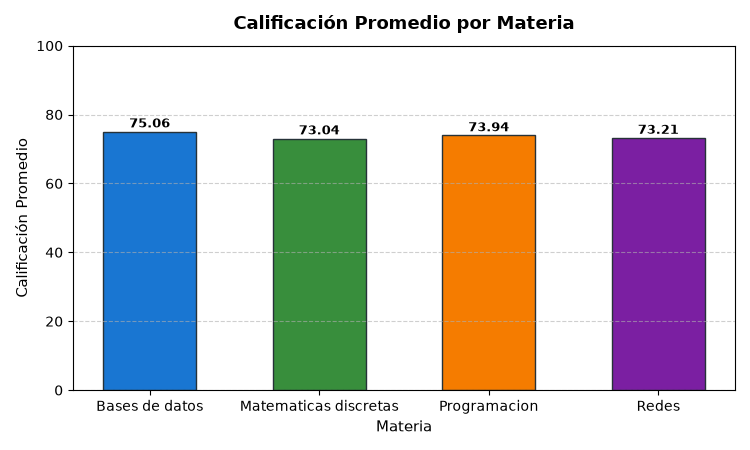

In [6]:
# 5.1 Gráfica de Barras: Promedio por Materia
fig1, ax1 = plt.subplots(figsize=(8, 5))
colores_barras = ["#1976D2", "#388E3C", "#F57C00", "#7B1FA2"]
barras = ax1.bar(
    promedio_materia.index,
    promedio_materia.values,
    color=colores_barras,
    edgecolor="#263238",
    width=0.55
)

ax1.set_title("Calificación Promedio por Materia", fontsize=14, fontweight="bold", pad=15)
ax1.set_xlabel("Materia", fontsize=12)
ax1.set_ylabel("Calificación Promedio", fontsize=12)
ax1.set_ylim(0, 100)
ax1.grid(axis="y", linestyle="--", alpha=0.6)

# Etiquetas numéricas sobre cada barra
for barra in barras:
    altura = barra.get_height()
    ax1.annotate(
        f"{altura:.2f}",
        xy=(barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.tight_layout()
# Regla de la práctica: plt.savefig() ANTES de plt.show()
plt.savefig("promedio_materias.png", dpi=300)
print("-> Gráfica 'promedio_materias.png' guardada exitosamente.")
plt.show()

**Vista previa de la imagen guardada (`promedio_materias.png`):**  
![Calificación Promedio por Materia](promedio_materias.png)

---
### 5.2 Histograma: Distribución de Calificaciones
Distribución general de frecuencias de las calificaciones de los estudiantes, destacando la línea de aprobación institucional (70):

-> Gráfica 'histograma.png' guardada exitosamente.


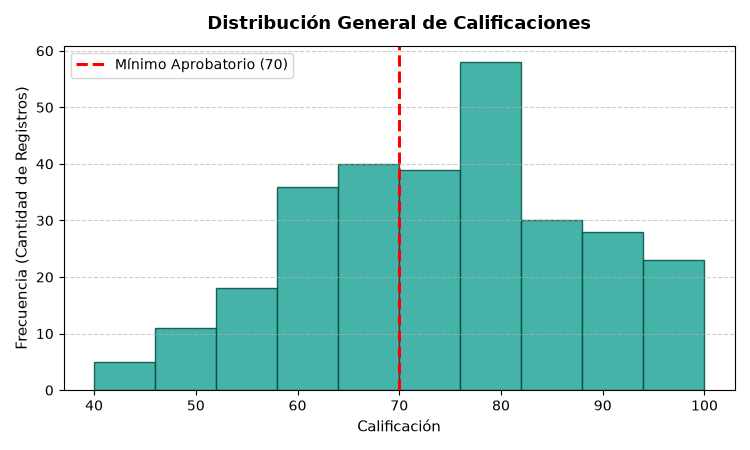

In [7]:
# 5.2 Histograma: Distribución de Calificaciones
fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.hist(df["calificacion"], bins=10, color="#26A69A", edgecolor="#004D40", alpha=0.85)
ax2.axvline(x=70, color="red", linestyle="--", linewidth=2.5, label="Mínimo Aprobatorio (70)")

ax2.set_title("Distribución General de Calificaciones", fontsize=14, fontweight="bold", pad=15)
ax2.set_xlabel("Calificación", fontsize=12)
ax2.set_ylabel("Frecuencia (Cantidad de Registros)", fontsize=12)
ax2.legend(fontsize=11, loc="upper left")
ax2.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("histograma.png", dpi=300)
print("-> Gráfica 'histograma.png' guardada exitosamente.")
plt.show()

**Vista previa de la imagen guardada (`histograma.png`):**  
![Distribución de Calificaciones](histograma.png)

---
### 5.3 Gráfica de Líneas: Tendencia por Unidad según Materia
Evolución y trayectoria del rendimiento académico a lo largo de las Unidades 1, 2 y 3 para cada asignatura:

-> Gráfica 'tendencia_unidades.png' guardada exitosamente.


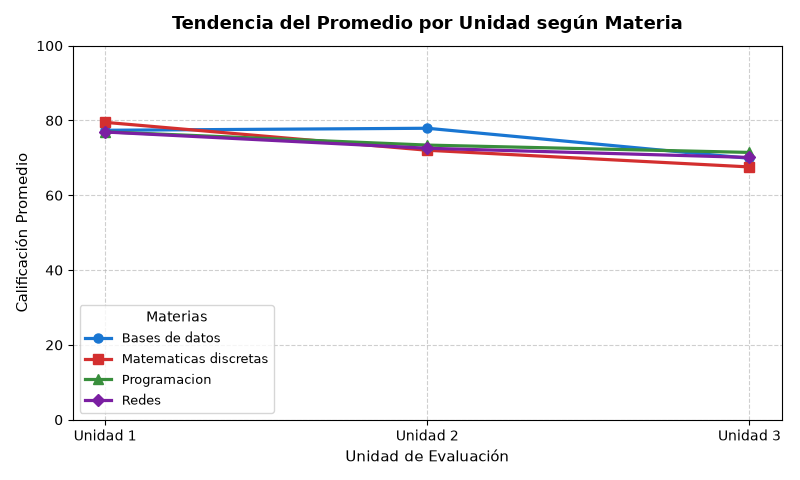

In [8]:
# 5.3 Gráfica de Líneas: Tendencia por Unidad para cada Materia
pivot_tendencia = df.pivot_table(index="unidad", columns="materia", values="calificacion", aggfunc="mean").round(2)
fig3, ax3 = plt.subplots(figsize=(9, 5.5))
marcadores = ["o", "s", "^", "D"]
colores_lineas = ["#1976D2", "#D32F2F", "#388E3C", "#7B1FA2"]

for idx, col in enumerate(pivot_tendencia.columns):
    ax3.plot(
        pivot_tendencia.index,
        pivot_tendencia[col],
        marker=marcadores[idx % len(marcadores)],
        color=colores_lineas[idx % len(colores_lineas)],
        linewidth=2.5,
        markersize=7,
        label=col
    )

ax3.set_title("Tendencia del Promedio por Unidad según Materia", fontsize=14, fontweight="bold", pad=15)
ax3.set_xlabel("Unidad de Evaluación", fontsize=12)
ax3.set_ylabel("Calificación Promedio", fontsize=12)
ax3.set_xticks([1, 2, 3])
ax3.set_xticklabels(["Unidad 1", "Unidad 2", "Unidad 3"])
ax3.set_ylim(0, 100)
ax3.legend(title="Materias", fontsize=10, loc="lower left")
ax3.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("tendencia_unidades.png", dpi=300)
print("-> Gráfica 'tendencia_unidades.png' guardada exitosamente.")
plt.show()

**Vista previa de la imagen guardada (`tendencia_unidades.png`):**  
![Tendencia por Unidad](tendencia_unidades.png)

---
## Ejercicio 6: Lectura de Resultados e Interpretación

A continuación se presentan las respuestas detalladas a las tres interrogantes planteadas en la práctica, sustentadas con las métricas obtenidas y los gráficos visualizados:

### 1. ¿Qué materia quedó con el promedio más bajo?
* **Respuesta:** La materia con el promedio más bajo fue **Matemáticas discretas** con un promedio de **73.04** (seguida de cerca por *Redes* con **73.21**).
* **Justificación:** Se corrobora tanto en la agregación `df.groupby('materia')` como en el gráfico de barras `promedio_materias.png`, donde su barra presenta la menor altura en la escala de 0 a 100.

### 2. ¿El promedio general de la unidad 3 es menor que el de las unidades 1 y 2?
* **Respuesta:** **Sí.**
* **Justificación:** Al calcular el promedio global por unidad:
  * **Unidad 1:** 77.69
  * **Unidad 2:** 73.99
  * **Unidad 3:** 69.76  
  Existe una clara tendencia a la baja a lo largo del semestre. La Unidad 3 no solo es menor que la 1 y la 2, sino que además cae por debajo del umbral mínimo aprobatorio institucional (70). Esto se visualiza con las pendientes negativas en `tendencia_unidades.png`.

### 3. ¿Cuántos alumnos quedan bajo 70 en su promedio general?
* **Respuesta:** Exactamente **2 alumnos**.
* **Justificación:** Al consultar `promedios_alumnos.csv`:
  * `ISC240119` (Héctor Vargas): **66.33**
  * `ISC240109` (Roberto Flores): **65.75**  
  Los 22 alumnos restantes (91.7% de la generación) obtuvieron un promedio general aprobatorio (>= 70).

In [9]:
# Verificación computacional de las respuestas del Ejercicio 6
materia_min = promedio_materia.idxmin()
val_min = promedio_materia.min()
u1, u2, u3 = promedio_por_unidad[1], promedio_por_unidad[2], promedio_por_unidad[3]
es_u3_menor = (u3 < u1) and (u3 < u2)
alumnos_bajo_70 = (df_promedios_export["promedio"] < 70).sum()

print("=" * 60)
print("VERIFICACIÓN AUTOMÁTICA DE RESULTADOS (EJERCICIO 6)")
print("=" * 60)
print(f"1. Materia con menor promedio: {materia_min} ({val_min:.2f})")
print(f"2. Promedios por unidad -> U1: {u1:.2f} | U2: {u2:.2f} | U3: {u3:.2f}")
print(f"   ¿Es la unidad 3 menor que la unidad 1 y 2?: {'SÍ' if es_u3_menor else 'NO'}")
print(f"3. Alumnos con promedio general < 70: {alumnos_bajo_70} alumno(s)")
print("=" * 60)

VERIFICACIÓN AUTOMÁTICA DE RESULTADOS (EJERCICIO 6)
1. Materia con menor promedio: Matematicas discretas (73.04)
2. Promedios por unidad -> U1: 77.69 | U2: 73.99 | U3: 69.76
   ¿Es la unidad 3 menor que la unidad 1 y 2?: SÍ
3. Alumnos con promedio general < 70: 2 alumno(s)
